# Pulse360: GenAI Employee Intelligence & Workforce Wellness Agent (Simulation)

Self-contained hackathon simulation: synthetic Jira, ServiceNow, LMS and HR4U telemetry is unified (bronze to silver to gold), rolling 30/90-day metrics and burnout-risk alerts are computed in PySpark, and a role-aware conversational agent answers manager/HR questions using retrieval plus an LLM (with a deterministic fallback). No catalogs or tables are created; everything runs in memory.

## PROOF plan: what we prove and how we show it

| # | PROOF item | Pulse360 answer |
| --- | --- | --- |
| 1 | **Business outcome** | **Decision improved:** when a manager or HRBP should step in on workload, leave and wellbeing, and how to rate people fairly at appraisal time. **Value:** catch burnout early, before it turns into regretted attrition, cut the time managers spend preparing 360 reviews, and reduce recency bias (Appraisal Guidelines, POL-004). *Hackathon targets (assumptions, not measured):* flag at-risk employees 4+ weeks earlier than an exit interview would, and get appraisal prep from about 2 h down to under 10 min per report. |
| 2 | **Technical outcome** | Combine 4 sources into one gold row per employee, compute explainable 30/90-day metrics, a burnout risk score (0-100), an overload alert and an impact score, apply role-based row and column security, and answer natural-language questions using retrieval plus an LLM, with a deterministic fallback. **Success criteria:** (a) 100% of source records resolve to an employee; (b) every simulated *overloaded* employee is High risk and alerted, with 0 false alerts; (c) a manager can never see another team's data; (d) the agent answers from context with cited metrics, and still works when the LLM is off. |
| 3 | **Intended user / audience** | **Experience the problem:** line managers (EMP1001-EMP1005), HR business partners (HR01) and employees (own data only). **Judge usefulness:** HR leadership and engineering managers (business fit), and hackathon judges (technical depth, governance, demo clarity). |
| 4 | **Required data and access** | **Data:** Jira (issues, story points, timestamps), ServiceNow (tickets, wellness category), LMS (course completions), HR4U (leave and attendance), manager notes and 6 policy docs. All are synthetic and in memory (no catalogs or tables). **Models/tools:** `ai_query` on `system.ai.claude-sonnet-4-5`, TF-IDF retrieval standing in for Vector Search. **Access:** serverless CPU compute, permission to call the model; in production, Unity Catalog row filters and column masks plus `hrbp` / manager groups. |
| 5 | **Demo flow and output** | **Input:** raw Jira, ServiceNow, LMS and HR4U data -> **Silver:** match every record to one employee -> **Gold:** metrics and risk/impact scores -> **Governance:** secure view for each role -> **Agent:** question -> intent -> tools -> answer. **End artifacts:** the `gold_employee_360` view, burnout alerts with reasons, the role-aware agent answer (section 9 script and the interactive widgets), and the wellness dashboard (section 10). |

### Major milestones

| Milestone | Status | Evidence in this notebook |
| --- | --- | --- |
| First data signal | Done | Section 2: all 5 sources resolve 100% (for example 2,653 Jira and 3,390 attendance rows). |
| First validated result | Done | Section 4: all 8 *overloaded* employees are High risk and alerted; no other persona is alerted. |
| End-to-end happy path | Done | Section 9 and the *Ask Pulse360* widget cell: a manager question returns an LLM answer limited to that manager's own reports, with PII masked. |
| Demo lock | To do before presenting | Checklist below. |

**Demo lock checklist**
* `SEED = 42` and `AS_OF = 2026-10-28` frozen (section 1), so the numbers match across runs.
* Run all cells in a clean session once without errors, and confirm section 4 still shows 8/8 overloaded alerts.
* Confirm the LLM is online (section 7); keep `USE_LLM = False` as a backup in case the model isn't reachable.
* Rehearse 3 widget questions: burnout risk on my team, least performing reports, leave carry-forward policy.

**Known limitations (state them up front)**
* The validation is circular by design: the synthetic data was generated to contain the signals the score looks for. It proves the logic works, not that it predicts real burnout.
* Disengagement is only reflected through a low impact score; there is no dedicated disengagement score yet.
* The scoring weights were set by hand and would need tuning against real HR outcomes such as attrition or survey data.

In [0]:
import re
import numpy as np
import pandas as pd
from datetime import date, datetime, timedelta
from pyspark.sql import functions as F, Window

# ---------------- Simulation config ----------------
SEED = 42
rng = np.random.default_rng(SEED)
AS_OF = date(2026, 10, 28)          # "today" for rolling windows
HISTORY_DAYS = 120
START = AS_OF - timedelta(days=HISTORY_DAYS - 1)
DAYS = [START + timedelta(days=d) for d in range(HISTORY_DAYS)]
N_EMP = 40

FIRST = ["Aarav", "Priya", "Rohan", "Sneha", "Vikram", "Ananya", "Karthik", "Meera", "Arjun", "Divya",
         "Rahul", "Kavya", "Siddharth", "Ishita", "Nikhil", "Pooja", "Aditya", "Riya", "Manish", "Neha",
         "Varun", "Tanvi", "Kunal", "Shreya", "Harsh", "Nisha", "Yash", "Aditi", "Gaurav", "Simran",
         "Rohit", "Anjali", "Deepak", "Swati", "Amit", "Lakshmi", "Suresh", "Farah", "Kabir", "Zoya"]
LAST = ["Sharma", "Iyer", "Reddy", "Nair", "Gupta", "Menon", "Patel", "Rao", "Kapoor", "Joshi"]
DEPTS = ["Data Engineering", "Platform", "Analytics", "ML Engineering", "IT Support"]
TITLES = {"Data Engineering": "Data Engineer", "Platform": "Platform Engineer", "Analytics": "Data Analyst",
          "ML Engineering": "ML Engineer", "IT Support": "Support Engineer"}

# Hidden ground-truth personas (used only to validate the risk model, never exposed to the agent)
FORCED = {7: "overloaded", 13: "overloaded", 22: "overloaded", 31: "overloaded",
          9: "disengaged", 26: "disengaged", 18: "learner"}

employees = []
for i in range(N_EMP):
    dept = DEPTS[i % len(DEPTS)]
    is_mgr = i < len(DEPTS)
    persona = "balanced" if is_mgr else FORCED.get(
        i, str(rng.choice(["balanced", "overloaded", "disengaged", "learner"], p=[0.6, 0.1, 0.15, 0.15])))
    emp_no = 1001 + i
    fn, ln = FIRST[i], LAST[i % len(LAST)]
    employees.append({
        "emp_id": f"EMP{emp_no}", "full_name": f"{fn} {ln}", "first_name": fn,
        "department": dept, "job_title": f"{dept} Manager" if is_mgr else TITLES[dept],
        "manager_id": None if is_mgr else f"EMP{1001 + (i % len(DEPTS))}",
        "persona": persona,
        # Source-system identifiers are deliberately inconsistent (identity resolution happens in silver)
        "email": f"{fn.lower()}.{ln.lower()}@pulse360.example.com",
        "sn_user": f"SN-{emp_no}", "lms_user": f"L{emp_no}", "hr_id": emp_no,
    })
emp_pd = pd.DataFrame(employees)

# ---------------- Jira: engineering output ----------------
COMPONENTS = ["ingestion", "billing", "customer360", "feature store", "CI/CD", "data quality",
              "access control", "reporting", "streaming", "API gateway"]
JIRA_TEMPLATES = ["Implement {c} pipeline", "Fix failing {c} job", "Optimize {c} performance",
                  "Add monitoring for {c}", "Refactor {c} module", "Resolve prod incident in {c}", "Design review for {c}"]
JIRA_RATE = {"balanced": 0.7, "overloaded": 1.4, "disengaged": 0.25, "learner": 0.5}
AFTER_HOURS_P = {"balanced": 0.08, "overloaded": 0.45, "disengaged": 0.04, "learner": 0.1}

jira_rows = []
for e in employees:
    p = e["persona"]
    for d in DAYS:
        weekday = d.weekday() < 5
        lam = JIRA_RATE[p] * (1.0 if weekday else (0.4 if p == "overloaded" else 0.03))
        if p == "overloaded" and (AS_OF - d).days < 45:
            lam *= 1.3                       # recent ramp-up
        if p == "disengaged" and (AS_OF - d).days < 30:
            lam *= 0.5                       # recent drop-off
        for _ in range(rng.poisson(lam)):
            after = (rng.random() < AFTER_HOURS_P[p]) or not weekday
            hour = int(rng.integers(20, 24)) if after else int(rng.integers(9, 18))
            jira_rows.append({
                "issue_key": f"PULSE-{len(jira_rows) + 1:05d}",
                "assignee_email": e["email"].upper() if rng.random() < 0.2 else e["email"],  # messy casing
                "issue_type": str(rng.choice(["Story", "Bug", "Task", "Incident"], p=[.45, .25, .2, .1])),
                "priority": str(rng.choice(["Low", "Medium", "High", "Critical"], p=[.2, .5, .22, .08])),
                "story_points": int(rng.choice([1, 2, 3, 5, 8], p=[.15, .3, .3, .18, .07])),
                "summary": str(rng.choice(JIRA_TEMPLATES)).format(c=str(rng.choice(COMPONENTS))),
                "resolved_ts": datetime(d.year, d.month, d.day, hour, int(rng.integers(0, 60))),
            })

# ---------------- ServiceNow: IT/HR service requests ----------------
SN_CATS = {"IT Access": ["Request workspace access", "VPN access issue after hours"],
           "Hardware": ["Laptop running slow", "Monitor replacement"],
           "HR Query": ["Payroll clarification", "Update bank details"],
           "Wellness": ["Request EAP counselling information", "Ergonomic chair request"],
           "Software": ["Install IDE license", "Upgrade Python environment"]}
SN_RATE = {"balanced": 0.04, "overloaded": 0.06, "disengaged": 0.05, "learner": 0.04}
SN_CAT_P = {"overloaded": [.3, .15, .1, .3, .15]}

sn_rows = []
for e in employees:
    p = e["persona"]
    for d in DAYS:
        if rng.random() < SN_RATE[p]:
            cat = str(rng.choice(list(SN_CATS), p=SN_CAT_P.get(p, [.3, .2, .2, .05, .25])))
            sn_rows.append({"number": f"INC{100000 + len(sn_rows)}", "opened_by": e["sn_user"], "category": cat,
                            "short_description": str(rng.choice(SN_CATS[cat])), "opened_date": d,
                            "state": str(rng.choice(["Resolved", "In Progress", "New"], p=[.75, .15, .1]))})

# ---------------- LMS: learning completions ----------------
COURSES = [("Databricks Lakehouse Fundamentals", 2.0), ("Advanced PySpark", 6.0), ("Generative AI Engineering", 8.0),
           ("Unity Catalog Governance", 3.0), ("Leadership Essentials", 4.0), ("Mindfulness at Work", 1.5),
           ("MLflow for MLOps", 5.0)]
LMS_RATE = {"balanced": 0.02, "overloaded": 0.004, "disengaged": 0.008, "learner": 0.07}
lms_rows = []
for e in employees:
    for d in DAYS:
        if rng.random() < LMS_RATE[e["persona"]]:
            title, hrs = COURSES[int(rng.integers(len(COURSES)))]
            lms_rows.append({"lms_user": e["lms_user"], "course_title": title, "hours": hrs,
                             "completion_date": d, "score": int(rng.integers(60, 101))})

# ---------------- HR4U: leave + attendance ----------------
leave_rows, att_rows = [], []
for e in employees:
    p = e["persona"]
    if p == "overloaded":   # at most one old leave, nothing in the last 90 days
        n_leaves, max_start = int(rng.random() < 0.5), HISTORY_DAYS - 95
    else:
        n_leaves, max_start = max(1, int(rng.poisson(4 if p == "disengaged" else 2.5))), HISTORY_DAYS - 3
    leave_days = set()
    for _ in range(n_leaves):
        start = START + timedelta(days=int(rng.integers(0, max_start)))
        ndays = int(rng.integers(1, 6 if p == "disengaged" else 4))
        end = start + timedelta(days=ndays - 1)
        leave_rows.append({"hr_id": e["hr_id"], "leave_type": str(rng.choice(["Casual", "Sick", "Earned"])),
                           "leave_start": start, "leave_end": end, "days": ndays, "status": "Approved"})
        leave_days |= {start + timedelta(days=k) for k in range(ndays)}
    mean_hours = {"balanced": 8.2, "overloaded": 10.4, "disengaged": 7.1, "learner": 8.0}[p]
    for d in DAYS:
        if d in leave_days:
            continue
        if d.weekday() < 5:
            hrs = rng.normal(mean_hours, 0.7)
        elif p == "overloaded" and rng.random() < 0.35:
            hrs = rng.normal(5.0, 1.0)
        else:
            continue
        att_rows.append({"hr_id": e["hr_id"], "work_date": d, "hours_logged": round(float(np.clip(hrs, 3, 14)), 1)})

# ---------------- Unstructured: performance notes + policy docs ----------------
NOTE_TEMPLATES = {
    "overloaded": ["Consistently delivers critical fixes and often picks up incidents outside working hours.",
                   "Has become the go-to person for {c}; single point of failure risk. Has not taken time off this quarter.",
                   "Exceptional ownership on the {c} migration, but appeared fatigued in the last sprint retro."],
    "balanced": ["Steady contributor on {c}; collaborates well with peers.",
                 "Delivered {c} improvements on time with good documentation.",
                 "Mentors junior engineers on {c} best practices."],
    "disengaged": ["Output on {c} has dropped compared to the previous quarter; needs clearer goals.",
                   "Missed two sprint commitments; would benefit from a career conversation.",
                   "Low participation in design reviews for {c}."],
    "learner": ["Actively upskilling; completed multiple certifications this quarter.",
                "Applied new GenAI skills to prototype a {c} assistant.",
                "Shows a strong growth mindset; ready for stretch assignments on {c}."],
}
notes_rows = []
for e in employees:
    for t in rng.choice(NOTE_TEMPLATES[e["persona"]], size=2, replace=False):
        notes_rows.append({"emp_id": e["emp_id"], "note_date": AS_OF - timedelta(days=int(rng.integers(1, 90))),
                           "note_text": str(t).format(c=str(rng.choice(COMPONENTS)))})

POLICY_DOCS = [
    {"doc_id": "POL-001", "title": "Leave Policy",
     "text": "Employees receive 24 earned leave days per year. Employees are encouraged to take at least 5 consecutive days off "
             "every 6 months. Up to 10 unused leave days can be carried forward to the next year; the rest lapse."},
    {"doc_id": "POL-002", "title": "Overtime and Right to Disconnect",
     "text": "Work after 8 pm and on weekends should be the exception. More than 3 after-hours days per week is flagged to the "
             "manager. Weekend work earns compensatory time off within 30 days."},
    {"doc_id": "POL-003", "title": "Wellness Program and EAP",
     "text": "The Employee Assistance Program offers 6 free confidential counselling sessions per year for burnout, stress and "
             "personal concerns. Mindfulness at Work courses are available in the LMS."},
    {"doc_id": "POL-004", "title": "Performance Appraisal Guidelines",
     "text": "Appraisals must be evidence-based and use 360-degree data across the full review period to avoid recency bias. "
             "Managers should recognise high-impact contributions and consider workload sustainability."},
    {"doc_id": "POL-005", "title": "Learning and Development",
     "text": "Each employee has a 40 hour per year learning budget. Certification exam fees are reimbursed after successful completion."},
    {"doc_id": "POL-006", "title": "Privacy for People Analytics",
     "text": "Managers can view only their direct reports. Wellness ticket details are visible only to HR business partners. "
             "Personal identifiers are masked in manager views."},
]

# ---------------- Bronze layer (in-memory Spark DataFrames) ----------------
bronze = {
    "jira": spark.createDataFrame(pd.DataFrame(jira_rows)),
    "servicenow": spark.createDataFrame(pd.DataFrame(sn_rows)),
    "lms": spark.createDataFrame(pd.DataFrame(lms_rows)),
    "hr4u_leave": spark.createDataFrame(pd.DataFrame(leave_rows)),
    "hr4u_attendance": spark.createDataFrame(pd.DataFrame(att_rows)),
}
for name, df in bronze.items():
    df.createOrReplaceTempView(f"bronze_{name}")
    print(f"bronze_{name:16s} rows={df.count():>6}")
print("Persona mix (hidden ground truth):", emp_pd.persona.value_counts().to_dict())

bronze_jira             rows=  2653
bronze_servicenow       rows=   214
bronze_lms              rows=   109
bronze_hr4u_leave       rows=    87
bronze_hr4u_attendance  rows=  3390
Persona mix (hidden ground truth): {'balanced': 17, 'disengaged': 9, 'overloaded': 8, 'learner': 6}


In [0]:
# Map every source-system identifier to one canonical emp_id
id_map = spark.createDataFrame(emp_pd.drop(columns=["persona"]))
dim_employee = id_map.select("emp_id", "full_name", "first_name", "department", "job_title", "manager_id", "email", "hr_id")

silver_jira = (bronze["jira"]
    .withColumn("email_norm", F.lower(F.trim("assignee_email")))
    .join(id_map.select("emp_id", F.col("email").alias("email_norm")), "email_norm")
    .withColumn("resolved_date", F.to_date("resolved_ts"))
    .withColumn("is_after_hours", (F.hour("resolved_ts") >= 20) | F.dayofweek("resolved_ts").isin(1, 7))
    .drop("assignee_email", "email_norm"))
silver_sn = bronze["servicenow"].join(id_map.select("emp_id", F.col("sn_user").alias("opened_by")), "opened_by").drop("opened_by")
silver_lms = bronze["lms"].join(id_map.select("emp_id", "lms_user"), "lms_user").drop("lms_user")
silver_leave = bronze["hr4u_leave"].join(id_map.select("emp_id", "hr_id"), "hr_id").drop("hr_id")
silver_att = bronze["hr4u_attendance"].join(id_map.select("emp_id", "hr_id"), "hr_id").drop("hr_id")

# Data-quality check: every bronze record must resolve to an employee
checks = [("jira", silver_jira), ("servicenow", silver_sn), ("lms", silver_lms),
          ("hr4u_leave", silver_leave), ("hr4u_attendance", silver_att)]
dq = pd.DataFrame([{"source": n, "bronze_rows": bronze[n].count(), "silver_rows": s.count()} for n, s in checks])
dq["match_rate_pct"] = (100 * dq.silver_rows / dq.bronze_rows).round(1)
display(dq)

source,bronze_rows,silver_rows,match_rate_pct
jira,2653,2653,100.0
servicenow,214,214,100.0
lms,109,109,100.0
hr4u_leave,87,87,100.0
hr4u_attendance,3390,3390,100.0


In [0]:
asof = F.lit(AS_OF)

def last_n(col, n):
    """Date falls in the window (AS_OF - n, AS_OF]."""
    return (F.col(col) > F.date_sub(asof, n)) & (F.col(col) <= asof)

def cnt(cond):
    return F.sum(F.when(cond, 1).otherwise(0))

def sm(cond, val):
    return F.sum(F.when(cond, val).otherwise(0))

jira_m = silver_jira.groupBy("emp_id").agg(
    cnt(last_n("resolved_date", 30)).alias("issues_30d"),
    sm(last_n("resolved_date", 30), F.col("story_points")).alias("points_30d"),
    sm((F.col("resolved_date") <= F.date_sub(asof, 30)) & (F.col("resolved_date") > F.date_sub(asof, 60)),
       F.col("story_points")).alias("points_prev_30d"),
    sm(last_n("resolved_date", 90), F.col("story_points")).alias("points_90d"),
    cnt(last_n("resolved_date", 90) & F.col("priority").isin("High", "Critical")).alias("critical_90d"),
    cnt(last_n("resolved_date", 30) & F.col("is_after_hours")).alias("after_hours_30d"),
)
sn_m = silver_sn.groupBy("emp_id").agg(
    cnt(last_n("opened_date", 90)).alias("tickets_90d"),
    cnt(last_n("opened_date", 90) & (F.col("category") == "Wellness")).alias("wellness_tickets_90d"))
lms_m = silver_lms.groupBy("emp_id").agg(
    cnt(last_n("completion_date", 90)).alias("courses_90d"),
    sm(last_n("completion_date", 90), F.col("hours")).alias("learning_hours_90d"))
leave_m = silver_leave.groupBy("emp_id").agg(
    sm(last_n("leave_start", 90), F.col("days")).alias("leave_days_90d"),
    F.max(F.when(F.col("leave_end") <= asof, F.col("leave_end"))).alias("last_leave_date"))
att_m = silver_att.groupBy("emp_id").agg(
    F.round(F.avg(F.when(last_n("work_date", 30), F.col("hours_logged"))), 1).alias("avg_hours_30d"),
    cnt(last_n("work_date", 30) & (F.col("hours_logged") > 9.5)).alias("overtime_days_30d"),
    cnt(last_n("work_date", 30) & F.dayofweek("work_date").isin(1, 7)).alias("weekend_days_30d"))

METRICS = ["issues_30d", "points_30d", "points_prev_30d", "points_90d", "critical_90d", "after_hours_30d",
           "tickets_90d", "wellness_tickets_90d", "courses_90d", "learning_hours_90d", "leave_days_90d",
           "avg_hours_30d", "overtime_days_30d", "weekend_days_30d"]
clip01 = lambda c: F.least(F.greatest(c, F.lit(0.0)), F.lit(1.0))
all_rows = Window.orderBy  # small dimension (one row per employee) -> global ranking is fine

gold = (dim_employee
    .join(jira_m, "emp_id", "left").join(sn_m, "emp_id", "left").join(lms_m, "emp_id", "left")
    .join(leave_m, "emp_id", "left").join(att_m, "emp_id", "left")
    .fillna(0, subset=METRICS)
    .withColumn("days_since_last_leave", F.coalesce(F.datediff(asof, "last_leave_date"), F.lit(HISTORY_DAYS)))
    .withColumn("after_hours_ratio_30d", F.round(F.col("after_hours_30d") / F.greatest(F.col("issues_30d"), F.lit(1)), 2))
    .withColumn("velocity_trend_pct", F.round((F.col("points_30d") - F.col("points_prev_30d")) * 100
                                              / F.greatest(F.col("points_prev_30d"), F.lit(1)), 1))
    .withColumn("velocity_pctile", F.round(F.percent_rank().over(all_rows("points_90d")), 2))
    # Burnout risk score (0-100): explainable weighted signals
    .withColumn("burnout_risk_score", F.round(
          30 * F.col("velocity_pctile")
        + 25 * F.when(F.col("leave_days_90d") == 0, 1).otherwise(0)
        + 20 * clip01((F.col("avg_hours_30d") - 8.0) / 2.5)
        + 15 * clip01(F.col("after_hours_ratio_30d") / 0.4)
        + 10 * clip01(F.col("wellness_tickets_90d") / 2.0), 1))
    .withColumn("risk_tier", F.when(F.col("burnout_risk_score") >= 65, "High")
                              .when(F.col("burnout_risk_score") >= 40, "Medium").otherwise("Low"))
    # Headline rule from the abstract: high delivery velocity + zero leave in 90 days
    .withColumn("overload_alert", (F.col("velocity_pctile") >= 0.75) & (F.col("leave_days_90d") == 0))
    .withColumn("alert_reasons", F.concat_ws("; ",
        F.when(F.col("velocity_pctile") >= 0.75, F.lit("top-quartile delivery velocity")),
        F.when(F.col("leave_days_90d") == 0, F.lit("no leave taken in 90 days")),
        F.when(F.col("avg_hours_30d") > 9.5, F.format_string("avg %.1f h/day logged", F.col("avg_hours_30d"))),
        F.when(F.col("after_hours_ratio_30d") >= 0.3,
               F.format_string("%.0f%% of work after hours", F.col("after_hours_ratio_30d") * 100)),
        F.when(F.col("weekend_days_30d") >= 3, F.format_string("%d weekend days worked", F.col("weekend_days_30d"))),
        F.when(F.col("velocity_trend_pct") <= -40, F.lit("delivery dropped >40% vs prior month"))))
    # Impact score (0-100): delivery volume, critical work and growth
    .withColumn("impact_score", F.round(
          50 * F.col("velocity_pctile")
        + 30 * F.percent_rank().over(all_rows("critical_90d"))
        + 20 * F.percent_rank().over(all_rows("learning_hours_90d")), 1))
)
gold.createOrReplaceTempView("gold_employee_360")
gold_pd = gold.toPandas()

display(gold.select("emp_id", "full_name", "department", "points_30d", "points_90d", "velocity_trend_pct",
                    "leave_days_90d", "avg_hours_30d", "after_hours_ratio_30d", "burnout_risk_score",
                    "risk_tier", "overload_alert", "alert_reasons", "impact_score")
            .orderBy(F.desc("burnout_risk_score")))

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(
/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


emp_id,full_name,department,points_30d,points_90d,velocity_trend_pct,leave_days_90d,avg_hours_30d,after_hours_ratio_30d,burnout_risk_score,risk_tier,overload_alert,alert_reasons,impact_score
EMP1009,Arjun Kapoor,ML Engineering,118,312,4.4,0,10.4,0.68,94.7,High,true,top-quartile delivery velocity; no leave taken in 90 days; avg 10.4 h/day logged; 68% of work after hours,68.7
EMP1023,Kunal Reddy,Analytics,107,337,-24.6,0,10.0,0.49,93.6,High,true,top-quartile delivery velocity; no leave taken in 90 days; avg 10.0 h/day logged; 49% of work after hours; 3 weekend days worked,72.9
EMP1008,Meera Rao,Analytics,142,371,25.7,0,10.5,0.54,89.1,High,true,top-quartile delivery velocity; no leave taken in 90 days; avg 10.5 h/day logged; 54% of work after hours,84.7
EMP1014,Ishita Nair,ML Engineering,137,338,30.5,0,9.3,0.68,88.9,High,true,top-quartile delivery velocity; no leave taken in 90 days; 68% of work after hours; 5 weekend days worked,88.0
EMP1032,Anjali Iyer,Platform,194,511,28.5,0,9.8,0.49,84.4,High,true,top-quartile delivery velocity; no leave taken in 90 days; avg 9.8 h/day logged; 49% of work after hours; 3 weekend days worked,80.0
EMP1025,Harsh Gupta,IT Support,132,331,36.1,0,9.4,0.49,83.2,High,true,top-quartile delivery velocity; no leave taken in 90 days; 49% of work after hours; 4 weekend days worked,74.2
EMP1035,Amit Gupta,IT Support,146,305,58.7,0,9.6,0.54,82.4,High,true,top-quartile delivery velocity; no leave taken in 90 days; avg 9.6 h/day logged; 54% of work after hours; 4 weekend days worked,64.8
EMP1018,Riya Rao,Analytics,109,320,-16.8,0,9.8,0.55,80.5,High,true,top-quartile delivery velocity; no leave taken in 90 days; avg 9.8 h/day logged; 55% of work after hours; 3 weekend days worked,78.1
EMP1001,Aarav Sharma,Data Engineering,61,160,45.2,0,8.1,0.0,48.0,Medium,false,no leave taken in 90 days,57.8
EMP1040,Zoya Joshi,IT Support,55,177,-28.6,2,8.5,0.18,39.5,Low,false,top-quartile delivery velocity,66.9


In [0]:
# Sanity check: the simulated 'overloaded' persona should land in High risk / overload alerts
val = gold_pd.merge(emp_pd[["emp_id", "persona"]], on="emp_id")
display(pd.crosstab(val.persona, val.risk_tier).reset_index())
print("Overload alerts by persona:", val[val.overload_alert].persona.value_counts().to_dict())

persona,High,Low,Medium
balanced,0,16,1
disengaged,0,9,0
learner,0,6,0
overloaded,8,0,0


Overload alerts by persona: {'overloaded': 8}


In [0]:
# Mirrors Unity Catalog row filters + column masks. In production this would be, e.g.:
#   CREATE FUNCTION rls_reports(manager_id STRING) RETURN is_account_group_member('hrbp') OR manager_id = <requester emp_id>;
#   ALTER TABLE gold_employee_360 SET ROW FILTER rls_reports ON (manager_id);
#   ALTER TABLE gold_employee_360 ALTER COLUMN email SET MASK mask_pii;
PII_COLS = ["email", "hr_id"]                 # masked for managers
HR_ONLY_COLS = ["wellness_tickets_90d"]       # visible only to HR business partners

def secure_view(df: pd.DataFrame, requester_id: str, role: str) -> pd.DataFrame:
    role = role.lower()
    if role == "hrbp":
        out = df.copy()
    elif role == "manager":
        out = df[df.manager_id == requester_id].copy()
    elif role == "employee":
        out = df[df.emp_id == requester_id].copy()
    else:
        raise PermissionError(f"Unknown role: {role}")
    if role == "manager":
        for c in PII_COLS:
            out[c] = "***MASKED***"
    if role != "hrbp":
        for c in HR_ONLY_COLS:
            out[c] = None
    return out

DEMO_MANAGER = "EMP1003"   # Analytics manager
mgr_view = secure_view(gold_pd, DEMO_MANAGER, "manager")
print(f"Manager {DEMO_MANAGER} sees {len(mgr_view)} of {len(gold_pd)} employees; HRBP sees {len(secure_view(gold_pd, 'HR01', 'hrbp'))}")
display(mgr_view[["emp_id", "full_name", "email", "hr_id", "wellness_tickets_90d", "risk_tier", "impact_score"]])

Manager EMP1003 sees 7 of 40 employees; HRBP sees 40


emp_id,full_name,email,hr_id,wellness_tickets_90d,risk_tier,impact_score
EMP1013,Siddharth Reddy,***MASKED***,***MASKED***,null,Low,27.7
EMP1033,Deepak Reddy,***MASKED***,***MASKED***,null,Low,52.9
EMP1028,Aditi Rao,***MASKED***,***MASKED***,null,Low,51.0
EMP1038,Farah Rao,***MASKED***,***MASKED***,null,Low,32.8
EMP1008,Meera Rao,***MASKED***,***MASKED***,null,High,84.7
EMP1023,Kunal Reddy,***MASKED***,***MASKED***,null,High,72.9
EMP1018,Riya Rao,***MASKED***,***MASKED***,null,High,78.1


In [0]:
# Stand-in for Databricks Vector Search: TF-IDF embeddings + cosine similarity
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

kb = [{"doc_id": d["doc_id"], "doc_type": "policy", "emp_id": None, "title": d["title"], "text": d["text"]}
      for d in POLICY_DOCS]
kb += [{"doc_id": f"NOTE-{i:03d}", "doc_type": "performance_note", "emp_id": n["emp_id"],
        "title": f"Manager note {n['note_date']}", "text": n["note_text"]} for i, n in enumerate(notes_rows)]

# Per-employee recent work summary (last 10 resolved Jira items)
recent = (silver_jira.withColumn("rn", F.row_number().over(Window.partitionBy("emp_id").orderBy(F.desc("resolved_ts"))))
          .filter("rn <= 10").groupBy("emp_id").agg(F.concat_ws("; ", F.collect_list("summary")).alias("text"))
          .toPandas())
kb += [{"doc_id": f"WORK-{r.emp_id}", "doc_type": "work_summary", "emp_id": r.emp_id,
        "title": "Recent Jira work", "text": r.text} for r in recent.itertuples()]
kb_pd = pd.DataFrame(kb)

vectorizer = TfidfVectorizer(ngram_range=(1, 2), stop_words="english", sublinear_tf=True)
kb_matrix = vectorizer.fit_transform(kb_pd["text"])

def vector_search(query, k=3, doc_types=None, emp_ids=None):
    sims = cosine_similarity(vectorizer.transform([query]), kb_matrix).ravel()
    res = kb_pd.assign(score=sims.round(3))
    if doc_types:
        res = res[res.doc_type.isin(doc_types)]
    if emp_ids is not None:
        res = res[res.emp_id.isna() | res.emp_id.isin(emp_ids)]
    return res.sort_values("score", ascending=False).head(k)

print(f"Indexed {len(kb_pd)} documents:", kb_pd.doc_type.value_counts().to_dict())
display(vector_search("how many unused leave days can I carry forward", doc_types=["policy"]))

Indexed 126 documents: {'performance_note': 80, 'work_summary': 40, 'policy': 6}


doc_id,doc_type,emp_id,title,text,score
POL-001,policy,null,Leave Policy,Employees receive 24 earned leave days per year. Employees are encouraged to take at least 5 consecutive days off every 6 months. Up to 10 unused leave days can be carried forward to the next year; the rest lapse.,0.506
POL-002,policy,null,Overtime and Right to Disconnect,Work after 8 pm and on weekends should be the exception. More than 3 after-hours days per week is flagged to the manager. Weekend work earns compensatory time off within 30 days.,0.107
POL-003,policy,null,Wellness Program and EAP,"The Employee Assistance Program offers 6 free confidential counselling sessions per year for burnout, stress and personal concerns. Mindfulness at Work courses are available in the LMS.",0.0


In [0]:
USE_LLM = True   # set False for a fully offline demo
LLM_CANDIDATES = ["system.ai.claude-sonnet-4-5", "databricks-meta-llama-3-3-70b-instruct"]
_llm = {"model": None, "disabled": not USE_LLM}

def llm_generate(prompt: str, max_chars: int = 6000):
    """Return LLM text, or None so callers can use a template answer."""
    if _llm["disabled"]:
        return None
    for m in ([_llm["model"]] if _llm["model"] else LLM_CANDIDATES):
        try:
            out = spark.sql(f"SELECT ai_query('{m}', :p) AS r", args={"p": prompt[:max_chars]}).first()["r"]
            _llm["model"] = m
            return out
        except Exception as ex:
            print(f"[LLM] {m} unavailable: {str(ex).splitlines()[0][:150]}")
    _llm["disabled"] = True
    print("[LLM] Falling back to deterministic template responses.")
    return None

print("LLM check ->", llm_generate("Reply with exactly: Pulse360 LLM online"), "| model:", _llm["model"])

LLM check -> Pulse360 LLM online | model: system.ai.claude-sonnet-4-5


In [0]:
SYSTEM_PROMPT = ("You are Pulse360, an empathetic, privacy-aware workforce intelligence assistant for managers and HR. "
                 "Answer ONLY from the provided context. Be concise (under 180 words), use bullet points, cite metrics, "
                 "frame burnout risk constructively, and never make medical diagnoses.")

def fmt_employee(r):
    reasons = f" - {r.alert_reasons}" if r.alert_reasons else ""
    return (f"{r.full_name} ({r.job_title}, {r.department}) as of {AS_OF}\n"
            f"* Delivery: {r.issues_30d} issues / {r.points_30d} story points in 30d ({r.velocity_trend_pct:+.0f}% vs prior 30d); "
            f"{r.points_90d} SP and {r.critical_90d} high/critical items in 90d\n"
            f"* Learning: {r.courses_90d} courses, {r.learning_hours_90d:.1f} h in 90d\n"
            f"* Service desk: {r.tickets_90d} tickets in 90d\n"
            f"* Wellness signals: {r.leave_days_90d} leave days in 90d, {r.days_since_last_leave} days since last leave, "
            f"avg {r.avg_hours_30d:.1f} h/day, {r.after_hours_ratio_30d:.0%} after-hours work, {r.weekend_days_30d} weekend days (30d)\n"
            f"* Burnout risk: {r.risk_tier} ({r.burnout_risk_score:.0f}/100){reasons}\n"
            f"* Impact score: {r.impact_score:.0f}/100")

def talking_points(r):
    tips = []
    if r.overload_alert or r.risk_tier == "High":
        tips.append("Recognise the high-impact delivery, then discuss workload balance and plan time off "
                    "(Leave Policy: 5 consecutive days every 6 months).")
    if r.after_hours_ratio_30d >= 0.3:
        tips.append("Review after-hours expectations per the Right to Disconnect guideline.")
    if r.velocity_trend_pct <= -40:
        tips.append("Delivery dipped vs last month - explore blockers, goal clarity and career aspirations.")
    if r.courses_90d >= 2:
        tips.append("Acknowledge the upskilling effort and offer a stretch assignment.")
    return tips or ["Steady performance - discuss growth goals and recognition."]

def find_employee(q, df):
    ql = q.lower()
    for r in df.itertuples():
        if r.full_name.lower() in ql:
            return r
    for r in df.itertuples():
        if re.search(rf"\b{r.first_name.lower()}\b", ql):
            return r
    return None

INTENTS = [("burnout", r"burn ?out|overload|at risk|wellness|exhaust|alert"),
           ("top", r"\btop\b|high[- ]impact|best|star|contributor"),
           ("policy", r"polic|how many|allowed|eligible|carry|reimburs|counsel|eap|disconnect"),
           ("least", r"least|worst|low.{0,10}perform|bottom|underperform|low impact|struggl|poor perform"),
           ("team", r"team|my reports|direct reports|overview")]

def classify(q, target):
    ql = q.lower()
    if target is not None and not re.search(INTENTS[2][1], ql):
        return "employee_360"
    for name, pat in INTENTS:
        if re.search(pat, ql):
            return name
    return "policy"

def pulse360_chat(question, requester_id, role):
    visible = secure_view(gold_pd, requester_id, role)
    target = find_employee(question, gold_pd)
    intent = classify(question, target)

    if intent == "employee_360":
        if target.emp_id not in set(visible.emp_id):
            answer = f"Access denied: {target.full_name} is outside your permitted scope as {role} (Privacy for People Analytics, POL-006)."
            return _show(question, role, intent, answer, llm_used=False)
        r = next(visible[visible.emp_id == target.emp_id].itertuples())
        docs = vector_search(f"{question} workload performance", k=3,
                             doc_types=["performance_note", "work_summary"], emp_ids=[r.emp_id])
        context = fmt_employee(r) + "\nEvidence:\n" + "\n".join(f"* [{d.title}] {d.text}" for d in docs.itertuples())
        fallback = context + "\nSuggested 1:1 talking points:\n" + "\n".join(f"* {t}" for t in talking_points(r))

    elif intent == "burnout":
        flagged = visible[(visible.risk_tier == "High") | visible.overload_alert].sort_values("burnout_risk_score", ascending=False)
        pol = vector_search("burnout counselling time off after hours", k=2, doc_types=["policy"])
        lines = [f"* {r.full_name} ({r.department}): {r.risk_tier} risk {r.burnout_risk_score:.0f}/100 - {r.alert_reasons}"
                 for r in flagged.itertuples()] or ["* No employees currently flagged High risk in your scope."]
        context = (f"{len(flagged)} of {len(visible)} employees in scope flagged:\n" + "\n".join(lines)
                   + "\nRelevant policy:\n" + "\n".join(f"* [{d.title}] {d.text}" for d in pol.itertuples()))
        fallback = context + "\nRecommended action: schedule supportive 1:1s, rebalance on-call load, and encourage planned leave."

    elif intent == "top":
        top = visible.sort_values("impact_score", ascending=False).head(5)
        context = "Top contributors by impact score (90d):\n" + "\n".join(
            f"* {r.full_name} ({r.department}): impact {r.impact_score:.0f}/100, {r.points_90d} SP, {r.critical_90d} high/critical, "
            f"{r.learning_hours_90d:.0f} h learning; burnout risk {r.risk_tier}" for r in top.itertuples())
        fallback = context + "\nNote: several top contributors also carry elevated burnout risk - recognise and protect them."

    elif intent == "team":
        tiers = visible.risk_tier.value_counts().to_dict()
        context = (f"Team overview ({len(visible)} people): {int(visible.points_30d.sum())} story points in 30d, "
                   f"avg {visible.avg_hours_30d.mean():.1f} h/day, risk tiers {tiers}, "
                   f"{int(visible.overload_alert.sum())} overload alerts.\n" + "\n".join(
                       f"* {r.full_name}: {r.points_30d} SP (30d), risk {r.risk_tier}, impact {r.impact_score:.0f}"
                       for r in visible.sort_values("impact_score", ascending=False).itertuples()))
        fallback = context

    elif intent == "least":
        bottom = visible.sort_values("impact_score").head(5)
        context = (f"Bottom 5 employees in your scope by impact score (90d):\n"
                   + "\n".join(
                       f"* {r.full_name} ({r.department}): impact {r.impact_score:.0f}/100, "
                       f"{r.points_90d} SP, velocity trend {r.velocity_trend_pct:+.0f}%, risk {r.risk_tier}"
                       for r in bottom.itertuples()))
        fallback = context + "\nNote: low impact may reflect recent onboarding, a role change, or disengagement — explore in a 1:1."

    else:  # policy question -> RAG over policy docs
        docs = vector_search(question, k=2, doc_types=["policy"])
        context = "\n".join(f"* [{d.title}] {d.text}" for d in docs.itertuples())
        fallback = "Based on company policy:\n" + context

    llm_answer = llm_generate(f"{SYSTEM_PROMPT}\n\nRequester role: {role}\n\nCONTEXT:\n{context}\n\nQUESTION: {question}")
    return _show(question, role, intent, llm_answer or fallback, llm_used=llm_answer is not None)

def _show(question, role, intent, answer, llm_used):
    print("=" * 100)
    print(f"[{role.upper()}] {question}")
    print(f"  -> intent: {intent} | generated by: {_llm['model'] if llm_used else 'template fallback'}")
    print("-" * 100)
    print(answer)
    return answer

In [0]:
mgr_team = gold_pd[gold_pd.manager_id == DEMO_MANAGER]
hot_report = mgr_team.sort_values("burnout_risk_score", ascending=False).iloc[0].full_name
low_report = mgr_team.sort_values("impact_score").iloc[0].first_name
outsider = gold_pd[(gold_pd.manager_id.notna()) & (gold_pd.manager_id != DEMO_MANAGER) & (gold_pd.risk_tier == "High")].iloc[0].full_name

pulse360_chat("Is anyone on my team at risk of burnout?", DEMO_MANAGER, "manager")
pulse360_chat(f"Give me a 360 summary of {hot_report} for our 1-on-1", DEMO_MANAGER, "manager")
pulse360_chat(f"How has {low_report} been doing this month?", DEMO_MANAGER, "manager")
pulse360_chat(f"Show me {outsider}'s performance", DEMO_MANAGER, "manager")
pulse360_chat("Who are the top high-impact contributors this quarter?", "HR01", "hrbp")
pulse360_chat("How many unused leave days can I carry forward?", "EMP1020", "employee");

[MANAGER] Is anyone on my team at risk of burnout?
  -> intent: burnout | generated by: system.ai.claude-sonnet-4-5
----------------------------------------------------------------------------------------------------
**Yes, 3 of 7 team members in Analytics show elevated burnout risk:**

**High-Risk Indicators:**
* **Kunal Reddy** (Risk: 94/100)
  - 10.0 h/day average, 49% after-hours work, 3 weekend days
* **Meera Rao** (Risk: 89/100)
  - 10.5 h/day average, 54% after-hours work
* **Riya Rao** (Risk: 80/100)
  - 9.8 h/day average, 55% after-hours work, 3 weekend days

**Common patterns:**
- All three maintain top-quartile delivery velocity
- None have taken leave in 90+ days
- After-hours work significantly exceeds policy thresholds (>3 days/week flagged)

**Recommended Actions:**
* **Immediate:** Discuss workload distribution and encourage use of compensatory time off for weekend work
* **Encourage leave:** All three are overdue for time off
* **Remind about resources:** EAP offers 6 

In [0]:
# Run this cell ONCE to create the widgets that appear at the top of this cell.
# After that, only re-run the NEXT cell each time you want a new answer.
dbutils.widgets.removeAll()

dbutils.widgets.text(
    "question",
    "Is anyone on my team at risk of burnout?",
    "💬 Ask Pulse360"
)
dbutils.widgets.dropdown(
    "role",
    "manager",
    ["manager", "hrbp", "employee"],
    "🔐 Your role"
)
dbutils.widgets.dropdown(
    "requester_id",
    "EMP1003",
    # Managers (EMP1001-EMP1005) each see their own ~7 direct reports
    # HR01 = HRBP, sees all 40 employees + wellness data
    # EMP1006+ = individual contributors, see only their own record
    ["EMP1001", "EMP1002", "EMP1003", "EMP1004", "EMP1005",  # managers
     "HR01",                                                    # hrbp
     "EMP1006", "EMP1010", "EMP1015", "EMP1020",              # employees
     "EMP1025", "EMP1030", "EMP1035", "EMP1040"],             # employees
    "🪪 Requester ID"
)

# Quick-action presets — overrides the question box when not set to default
dbutils.widgets.dropdown(
    "quick_action",
    "— use question box —",
    ["— use question box —",
     "Show my least performing reports",
     "Who is at risk of burnout on my team?",
     "Who are my top contributors this quarter?",
     "Give me a team overview",
     "What is the leave carry-forward policy?"],
    "⚡ Quick action"
)
# Focus employee — pick a specific person by name; auto-builds a 360 question
all_names = sorted(gold_pd.full_name.tolist())
dbutils.widgets.dropdown(
    "focus_employee",
    "— all (use question box) —",
    ["— all (use question box) —"] + all_names,
    "👤 Focus employee"
)

print("✓ Widgets ready (5 controls).")
print("  Managers : EMP1001 (Data Eng) · EMP1002 (Platform) · EMP1003 (Analytics) · EMP1004 (ML Eng) · EMP1005 (IT Support)")
print("  HRBP     : HR01  (sees all 40 employees)")
print("  Employee : EMP1006 – EMP1040  (sees own data only)")
print()
print("Widget priority:  ⚡ Quick action  >  👤 Focus employee  >  💬 Question box")
print("→ Adjust the widgets above, then run the next cell.")

✓ Widgets ready (5 controls).
  Managers : EMP1001 (Data Eng) · EMP1002 (Platform) · EMP1003 (Analytics) · EMP1004 (ML Eng) · EMP1005 (IT Support)
  HRBP     : HR01  (sees all 40 employees)
  Employee : EMP1006 – EMP1040  (sees own data only)

Widget priority:  ⚡ Quick action  >  👤 Focus employee  >  💬 Question box
→ Adjust the widgets above, then run the next cell.


In [0]:
question     = dbutils.widgets.get("question")
role         = dbutils.widgets.get("role")
req_id       = dbutils.widgets.get("requester_id")
quick_action = dbutils.widgets.get("quick_action")
focus_emp    = dbutils.widgets.get("focus_employee")

# Priority: ⚡ Quick action  >  👤 Focus employee  >  💬 Question box
if quick_action != "— use question box —":
    final_q = quick_action
elif focus_emp != "— all (use question box) —":
    final_q = f"Give me a 360 summary of {focus_emp}"
else:
    final_q = question

print(f"▶ [{role.upper()} / {req_id}]: {final_q}\n")
pulse360_chat(final_q, req_id, role)

# — Structured table: shown only when the question is about least/low performers —
if re.search(r"least|worst|low.{0,10}perform|bottom|underperform|low impact", final_q.lower()):
    visible_df = secure_view(gold_pd, req_id, role)
    sorted_df  = visible_df.sort_values("impact_score")

    # Show only genuinely underperforming employees:
    # impact < 60  OR  below the team median — whichever gives a smaller, meaningful set
    threshold  = min(60.0, float(visible_df.impact_score.median()))
    flagged    = sorted_df[sorted_df.impact_score < threshold]

    # Always show at least 1 row; never show more than half the team
    if len(flagged) == 0:
        flagged = sorted_df.head(1)
        note = "No employees are significantly below team average — showing the lowest-scoring member."
    else:
        max_rows = max(1, len(visible_df) // 2)
        flagged  = flagged.head(max_rows)
        note     = f"{len(flagged)} employee(s) with impact score below {threshold:.0f}/100 (team threshold)."

    bottom_df = (
        flagged
        [["full_name", "department", "impact_score", "points_90d",
          "velocity_trend_pct", "avg_hours_30d", "leave_days_90d", "risk_tier"]]
        .rename(columns={
            "full_name":          "Employee",
            "department":         "Department",
            "impact_score":       "Impact Score",
            "points_90d":         "Story Points (90d)",
            "velocity_trend_pct": "Velocity Trend %",
            "avg_hours_30d":      "Avg h/day (30d)",
            "leave_days_90d":     "Leave Days (90d)",
            "risk_tier":          "Burnout Risk",
        })
        .reset_index(drop=True)
    )
    bottom_df["Impact Score"]     = bottom_df["Impact Score"].apply(lambda x: f"{x:.0f} / 100")
    bottom_df["Velocity Trend %"] = bottom_df["Velocity Trend %"].apply(lambda x: f"{x:+.0f}%")
    print(f"\n📊 Underperforming employees: {note}")
    display(bottom_df)

▶ [MANAGER / EMP1003]: who is underperforming can you give me list

[MANAGER] who is underperforming can you give me list
  -> intent: least | generated by: system.ai.claude-sonnet-4-5
----------------------------------------------------------------------------------------------------
# Underperforming Team Members (90-day Impact Score)

Based on impact scores, here are your lowest performers:

**Critical Attention Needed:**
* **Siddharth Reddy** - Impact: 28/100, 70 SP delivered, velocity declining -38%
* **Farah Rao** - Impact: 33/100, 115 SP delivered, velocity declining -75% (steepest drop)

**Below Target:**
* **Aditi Rao** - Impact: 51/100, 130 SP, but velocity improving +97% (positive trend)
* **Deepak Reddy** - Impact: 53/100, 134 SP, stable velocity +5%

**Note on Kunal Reddy:**
* Impact: 73/100 (highest in this group), 337 SP (3x others)
* **High burnout risk** flagged with -25% velocity decline
* Consider supportive check-in despite stronger output

## Recommended Actions:
-

Employee,Department,Impact Score,Story Points (90d),Velocity Trend %,Avg h/day (30d),Leave Days (90d),Burnout Risk
Siddharth Reddy,Analytics,28 / 100,70,-38%,7.1,11,Low
Farah Rao,Analytics,33 / 100,115,-75%,8.2,0,Low
Aditi Rao,Analytics,51 / 100,130,+97%,7.9,3,Low


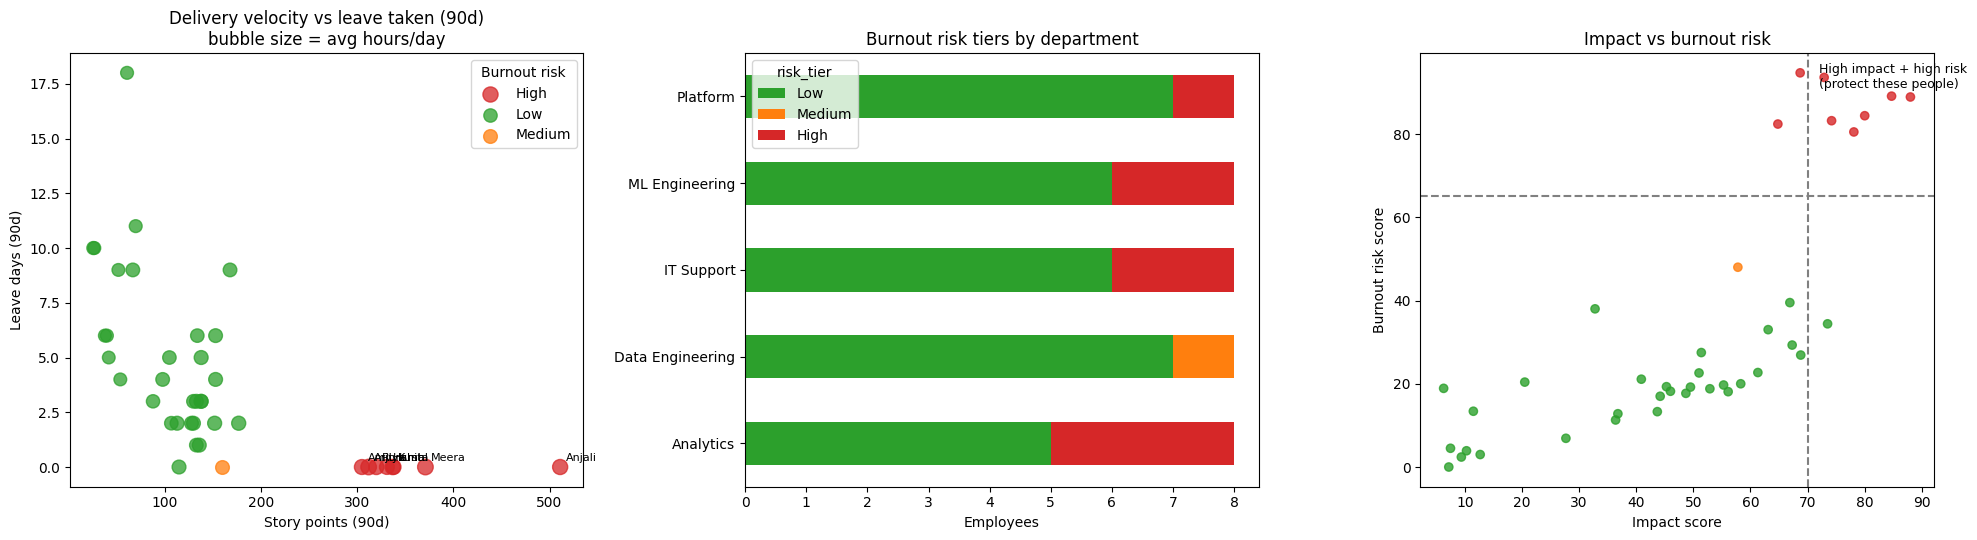

In [0]:
import matplotlib.pyplot as plt

COLORS = {"High": "#d62728", "Medium": "#ff7f0e", "Low": "#2ca02c"}
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

ax = axes[0]
for tier, g in gold_pd.groupby("risk_tier"):
    ax.scatter(g.points_90d, g.leave_days_90d, s=g.avg_hours_30d * 12, c=COLORS[tier], alpha=0.75, label=tier)
for r in gold_pd[gold_pd.overload_alert].itertuples():
    ax.annotate(r.first_name, (r.points_90d, r.leave_days_90d), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set(title="Delivery velocity vs leave taken (90d)\nbubble size = avg hours/day", xlabel="Story points (90d)", ylabel="Leave days (90d)")
ax.legend(title="Burnout risk")

ax = axes[1]
ct = pd.crosstab(gold_pd.department, gold_pd.risk_tier).reindex(columns=["Low", "Medium", "High"], fill_value=0)
ct.plot(kind="barh", stacked=True, color=[COLORS[c] for c in ct.columns], ax=ax)
ax.set(title="Burnout risk tiers by department", xlabel="Employees", ylabel="")

ax = axes[2]
ax.scatter(gold_pd.impact_score, gold_pd.burnout_risk_score, c=gold_pd.risk_tier.map(COLORS), alpha=0.8)
ax.axhline(65, ls="--", c="grey"); ax.axvline(70, ls="--", c="grey")
ax.text(72, 97, "High impact + high risk\n(protect these people)", fontsize=9, va="top")
ax.set(title="Impact vs burnout risk", xlabel="Impact score", ylabel="Burnout risk score")

plt.tight_layout()
plt.show()

## From simulation to production

| Simulated here | Production component |
| --- | --- |
| Synthetic Python generators | Jira / ServiceNow / LMS / HR4U REST APIs ingested via Lakeflow Jobs |
| In-memory `bronze_*` / `silver_*` / `gold_employee_360` DataFrames | Delta Lake tables in Unity Catalog (medallion layers) |
| `secure_view()` | Unity Catalog row filters and column masks on the gold table |
| TF-IDF `vector_search()` | Databricks Vector Search index with Delta auto-sync |
| `llm_generate()` via `ai_query` | Mosaic AI Model Serving / AI Gateway model service |
| Regex intent router + tool functions | LangGraph agent with function calling, logged in MLflow |
| `pulse360_chat()` | Slack Bolt / Teams bot or Databricks App (Streamlit) front-end |
| Rule-based burnout score | Same features, optionally an ML model trained on attrition labels |